# Evaluate an Architecture

This example evaluates a mission architecture: observing platforms of several kinds (satellites, radar stations, and surface stations), with the ground stations that receive the satellites' data, as one `Architecture`. It then measures the value of each member by leaving it out, and of candidates (a data relay and a proposed satellite) by adding each, as a pre-phase A study might compare a new mission with the systems that already observe its region.

The targets are points over the southern Great Plains (Oklahoma and the Texas Panhandle) at 1,500 m above the WGS 84 ellipsoid, a low cloud base, observed over three days.

In [1]:
from datetime import datetime, timedelta, timezone

from shapely.geometry import box
from tatc.generation import generate_points_fibonacci_lattice

start = datetime(2027, 5, 1, tzinfo=timezone.utc)
end = start + timedelta(days=3)
region = box(-103.0, 33.6, -94.4, 37.0)
points = generate_points_fibonacci_lattice(25e3, elevation=1500, mask=region)
print(len(points), "points")

600 points


The baseline comes from the system catalog (see _Use System Catalog_): the JPSS satellites NOAA-20 and NOAA-21 with VIIRS, the NEXRAD radars and the U.S. Climate Reference Network (USCRN) stations within the region, and the ground stations that receive JPSS data: NOAA's Fairbanks Command and Data Acquisition Station (FCDAS), KSAT's Svalbard and Troll stations, and McMurdo. The catalog warns of configurations that are not validated; the warnings are summarized.

In [2]:
import warnings

from tatc.catalog import get_system
from tatc.schemas import Architecture

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    jpss = get_system("jpss").build("ground_track", payload=["viirs"], time_step=10)
    radars = get_system("nexrad").build(region=region)
    stations = get_system("uscrn").build(region=region, radius=10000)
    downlinks = get_system("noaa_ground_stations").build("jpss")
print(len(caught), "warnings, such as:", caught[0].message)

baseline = Architecture(
    name="Baseline",
    satellites=jpss,
    radar_stations=radars,
    surface_platforms=stations,
    ground_stations=downlinks,
)
for field in ["satellites", "radar_stations", "surface_platforms", "ground_stations"]:
    print(f"{field}:", [member.name for member in getattr(baseline, field)])

3 warnings, such as: jpss:ground_track is partial, not validated: node_longitude_error_p95: 21.4217 fails the limit of 10; node_time_error_p95: 82.1715 fails the limit of 60
satellites: ['NOAA-20', 'NOAA-21']
radar_stations: ['KAMA', 'KFDR', 'KINX', 'KLBB', 'KTLX', 'KVNX']
surface_platforms: ['03054', '03055', '53182', '53926', '53927']
ground_stations: ['FCDAS', 'SvalSat', 'McMurdo', 'TrollSat']


The metrics are a function of the observations of every platform. Here they are:

- the longest gap: the longest time a target goes unobserved in the period (from its start to its end), averaged over the targets;
- the share of targets monitored without a gap (such as those within a radar's coverage, which observes them throughout the period);
- the mean latency of the satellites' observations: from each observation to its downlink (radars and surface stations have no data path in the architecture, so their observations have none).

In [3]:
import numpy as np
import pandas as pd
from tatc.utils import hash_geometry

hours = (end - start) / timedelta(hours=1)
keys = [hash_geometry(point) for point in points.geometry]


def longest_gaps(observations):
    """The longest time (hours) that each target goes unobserved."""
    gaps = pd.Series(hours, index=keys)
    for key, group in observations.groupby("target_hash"):
        longest, covered = timedelta(0), pd.Timestamp(start)
        for first, last in sorted(zip(group["start"], group["end"])):
            longest = max(longest, first - covered)
            covered = max(covered, last)
        longest = max(longest, pd.Timestamp(end) - covered)
        gaps[key] = longest / timedelta(hours=1)
    return gaps


def metrics(observations):
    gaps = longest_gaps(observations)
    latency = observations["latency"].dropna() / timedelta(minutes=1)
    return {
        "longest gap (h)": float(gaps.mean()),
        "monitored (%)": float(100 * (gaps == 0).mean()),
        "mean latency (min)": float(latency.mean()) if len(latency) else np.nan,
    }

`Architecture.evaluate` analyzes each platform (satellites from their orbits, radars and stations from their footprints, here at the targets' elevation of 1,500 m), the contacts of the satellites with the ground stations, and the downlink of each observation, then computes the metrics.

In [4]:
evaluation = baseline.evaluate(points, start, end, metrics, elevation=1500)
evaluation.metrics

{'longest gap (h)': 4.144089958020131,
 'monitored (%)': 64.0,
 'mean latency (min)': 22.86477071890702}

The observations name each platform in the column of its kind, with the ground station, time downlinked, and latency of the satellites' observations.

In [5]:
observations = evaluation.observations
kinds = (
    observations[["satellite", "radar_station", "surface_platform"]]
    .notna()
    .idxmax(axis=1)
)
display(observations.groupby(kinds).size().rename("observations").to_frame())
observations[observations.satellite.notna()][
    ["satellite", "start", "end", "ground_station", "downlinked", "latency"]
].head()

,observations
radar_station,463
satellite,9779
surface_platform,5


,satellite,start,end,ground_station,downlinked,latency
468,NOAA-21,2027-05-01 07:10:48.856529680+00:00,2027-05-01 07:15:00.974619603+00:00,McMurdo,2027-05-01 07:48:44.087681+00:00,0 days 00:35:59.183728465
469,NOAA-21,2027-05-01 07:10:54.318535218+00:00,2027-05-01 07:15:03.371160786+00:00,McMurdo,2027-05-01 07:48:44.087681+00:00,0 days 00:35:55.350337455
470,NOAA-21,2027-05-01 07:10:56.013189814+00:00,2027-05-01 07:14:57.454922358+00:00,McMurdo,2027-05-01 07:48:44.087681+00:00,0 days 00:35:57.587528257
471,NOAA-21,2027-05-01 07:10:58.168199047+00:00,2027-05-01 07:15:11.544120080+00:00,McMurdo,2027-05-01 07:48:44.087681+00:00,0 days 00:35:49.307205461
472,NOAA-21,2027-05-01 07:10:59.805532811+00:00,2027-05-01 07:15:05.723438356+00:00,McMurdo,2027-05-01 07:48:44.087681+00:00,0 days 00:35:51.527059080


## The value of each member

`leave_one_out` evaluates the architecture without each member (or group of members, such as a network of stations) from the analyses already done, and gives its contribution to each metric: the metric with it minus that without it (a negative contribution to a gap or a latency shortens it).

In [6]:
values = evaluation.leave_one_out(
    {
        "NOAA-20": "NOAA-20",
        "NOAA-21": "NOAA-21",
        "NEXRAD": [radar.name for radar in radars],
        "USCRN": [station.name for station in stations],
        **{station.name: station.name for station in downlinks},
    }
)
values.round(2)

,kind,longest gap (h),monitored (%),mean latency (min),longest gap (h) contribution,monitored (%) contribution,mean latency (min) contribution
member,,,,,,,
NOAA-20,satellite,4.41,64.00,22.07,-0.26,0.00,0.79
NOAA-21,satellite,4.41,64.00,23.49,-0.27,0.00,-0.63
NEXRAD,group,11.45,0.50,22.86,-7.31,63.50,0.00
USCRN,group,4.18,63.67,22.86,-0.04,0.33,0.00
FCDAS,ground_station,4.14,64.00,25.62,0.00,0.00,-2.76
SvalSat,ground_station,4.14,64.00,22.86,0.00,0.00,0.00
McMurdo,ground_station,4.14,64.00,38.92,0.00,0.00,-16.05
TrollSat,ground_station,4.14,64.00,22.86,0.00,0.00,0.00


NEXRAD monitors most targets throughout the period: without it, the longest gap grows to the time between satellite passes. The two JPSS satellites shorten the longest gap of the targets outside the radars' coverage. For latency, McMurdo matters most: it receives the data of the descending (night) passes, which otherwise wait for FCDAS on a later orbit, while FCDAS receives the data of the ascending passes. SvalSat and TrollSat contribute nothing for these targets, as FCDAS or McMurdo always receives their data first (TrollSat backs up McMurdo). A member can also lengthen a mean: NOAA-20's observations wait longer for a downlink than NOAA-21's over these days, so the mean latency is shorter without it.

## The value of candidates

`add_one` evaluates the architecture with each candidate, analyzing only the candidate. The candidates are:

- NASA's Tracking and Data Relay Satellite System (TDRS) from the catalog, as a relay (`build_relay`): its operational satellites, which the JPSS satellites contact by line of sight above 100 km (the catalog's entry is nominal: its longitudes are fitted to element sets, not yet tested);
- a proposed satellite with a thermal imager in a 22:30 sun-synchronous orbit, and the same satellite launched during the period, active from its second day (an `ActiveWindow`).

In [7]:
from tatc.schemas import ActiveWindow, PointedInstrument, Satellite, SunSynchronousOrbit

tdrs = get_system("tdrs").build_relay(min_grazing_altitude=100e3)
print(tdrs.name, [satellite.name for satellite in tdrs.satellites])
proposed = Satellite(
    name="Proposed",
    orbit=SunSynchronousOrbit(
        altitude=550e3, equator_crossing_time="22:30", epoch=start
    ),
    instruments=[
        PointedInstrument(
            name="Thermal imager",
            cross_track_field_of_view=40,
            along_track_field_of_view=1,
            is_rectangular=True,
            is_swept=True,
        )
    ],
)
candidates = evaluation.add_one(
    {
        "TDRS": tdrs,
        "Proposed": proposed,
        "Proposed (from day 2)": (
            proposed,
            ActiveWindow(start=start + timedelta(days=1)),
        ),
    }
)
candidates.round(2)

C:\Users\pgrogan1\github\tatc\src\tatc\catalog\system_schemas.py:1156: UserWarning: tdrs:slot is nominal, not validated: slot_longitude_error_p95: not tested; inclination_error_p95: not tested; test_sets: not tested; test_span_days: not tested; no comparison with reference data
  satellites = self.build(


tdrs ['TDRS 11', 'TDRS 12', 'TDRS 13']


,kind,longest gap (h),monitored (%),mean latency (min),longest gap (h) contribution,monitored (%) contribution,mean latency (min) contribution
member,,,,,,,
TDRS,relay,4.14,64.0,19.65,0.00,0.0,-3.21
Proposed,satellite,3.92,64.0,21.87,-0.22,0.0,-0.99
Proposed (from day 2),satellite,3.92,64.0,22.11,-0.22,0.0,-0.75


The relay shortens the mean latency only a little: data observed during a contact waits for the contact to end, as for a ground station (the default `during_contact="end"`), and contacts with a relay last most of an orbit. A relay that forwards data as it is observed is evaluated with `during_contact="immediate"`:

In [8]:
relayed = baseline.with_members(tdrs).evaluate(
    points,
    start,
    end,
    metrics,
    elevation=1500,
    during_contact="immediate",
)
relayed.metrics

{'longest gap (h)': 4.144089958020131,
 'monitored (%)': 64.0,
 'mean latency (min)': 0.0}

Every observation of these targets is made in view of a TDRS satellite, so its data is relayed as it is observed. The contributions of the members and the candidates (with the default downlink at the end of a contact), side by side:

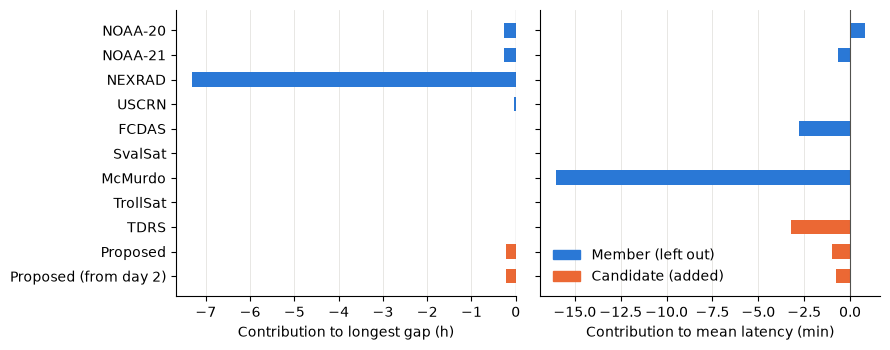

In [9]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

table = pd.concat([values.assign(group="Member"), candidates.assign(group="Candidate")])
colors = table.group.map({"Member": "#2a78d6", "Candidate": "#eb6834"})
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
for ax, metric in zip(axes, ["longest gap (h)", "mean latency (min)"]):
    ax.barh(table.index, table[f"{metric} contribution"], color=colors, height=0.6)
    ax.axvline(0, color="#52514e", lw=0.8)
    ax.set_xlabel(f"Contribution to {metric}")
    ax.grid(axis="x", color="#e4e3df", lw=0.6)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
axes[0].invert_yaxis()
handles = [
    Patch(color="#2a78d6", label="Member (left out)"),
    Patch(color="#eb6834", label="Candidate (added)"),
]
axes[1].legend(handles=handles, frameon=False, loc="lower left")
fig.tight_layout()
plt.show()

## In trade studies

A trade study builds an architecture for each design: `tatc.tradespace.ObservationStudy` takes a `build` function that returns an `Architecture` (or a list of satellites) and a `baseline` architecture that every design shares, such as the one above without its satellites that a design replaces. A mission plan deploys the design's satellites, while the baseline's members operate in every phase of the deployment. `ObservationStudy.evaluation_of(design)` gives the evaluation of a design's architecture, from the study's cached analyses, whose `leave_one_out` and `add_one` measure the value of its members as above.